In [32]:
from langgraph.graph import StateGraph, START, END
from langchain_anthropic import ChatAnthropic
from typing import TypedDict
from dotenv import load_dotenv

In [33]:
load_dotenv()

True

In [34]:
model = ChatAnthropic(model="claude-haiku-5-5")

In [35]:
class BlogState(TypedDict):
    title: str
    topic: str
    outline: str
    content: str
    feedback: str


In [36]:
graph = StateGraph(BlogState)

#node to generate title from topic
def generate_title(state:BlogState) -> BlogState:
    #fetch the title from the state and generate a catchy title using LLM
    topic = state["topic"]
    #form the title prompt to send to the LLM
    prompt = f"Generate a catchy blog title for the topic: {topic}"
    #ask that question to LLM and get the title
    title = model.invoke(prompt)
    #update the state with the title and return it
    state['title'] = title
    return state

In [37]:
#add node to the graph
graph.add_node(generate_title, name="generate_title", inputs=["topic"], outputs=["title"])

In [38]:
def create_outline(state:BlogState) -> BlogState:
    title = state["title"]
    prompt = f"Create a detailed outline for the blog titled: {title}"
    outline = model.invoke(prompt).content
    state['outline'] = outline
    return state

In [39]:
#add node to the graph
graph.add_node("create_outline", create_outline)

In [40]:
def create_content(state:BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    prompt = f"Write a full blog post titled: {title}\n\nFollow this outline:\n{outline}"
    content = model.invoke(prompt).content
    state['content'] = content
    return state

In [41]:
#add node and wire up the chain: START -> title -> outline -> content -> END
graph.add_node("create_content", create_content)

In [42]:
#I want to add a new node to graph to eavaluate the content generated by the LLM and provide feedback. The new node will be called "evaluate_content" and it will take the content as input and return feedback as output.
def evaluate_content(state:BlogState) -> BlogState:
    content = state["content"]
    prompt = f"Evaluate the following blog content and provide feedback:\n{content}"
    feedback = model.invoke(prompt).content
    state['feedback'] = feedback
    return state

In [43]:
graph.add_node("evaluate_content", evaluate_content)

In [44]:
graph.add_edge(START, "generate_title")
graph.add_edge("generate_title", "create_outline")
graph.add_edge("create_outline", "create_content")
graph.add_edge("create_content", "evaluate_content")
graph.add_edge("evaluate_content", END)

In [47]:
workflow = graph.compile()
initial_state = {'topic': 'Sunrise in mountains'}
result = workflow.invoke(initial_state)
print(result)

{'title': AIMessage(content='Here are a few catchy blog title options:\n\n1. **Chasing the Light: Witnessing Mountain Sunrises at Their Finest**\n2. **Where Mountains Meet the Morning Sky**\n3. **First Light, Highest Heights: The Magic of Mountain Sunrises**\n4. **Above the Clouds: Why Mountain Sunrises Are Worth Every Early Alarm**\n5. **Golden Peaks and Morning Hues: A Guide to Mountain Sunrises**', additional_kwargs={}, response_metadata={'id': 'msg_011Cg6Y8jnf84ba2SozNtfK4', 'container': None, 'diagnostics': None, 'model': 'claude-haiku-5-5', 'stop_details': None, 'stop_reason': 'end_turn', 'stop_sequence': None, 'usage': {'cache_creation': {'ephemeral_1h_input_tokens': 0, 'ephemeral_5m_input_tokens': 0}, 'cache_creation_input_tokens': 0, 'cache_read_input_tokens': 0, 'inference_geo': 'global', 'input_tokens': 32, 'output_tokens': 170, 'output_tokens_details': {'thinking_tokens': 0}, 'server_tool_use': None, 'service_tier': 'standard', 'speed': 'standard'}, 'model_name': 'claude-ha

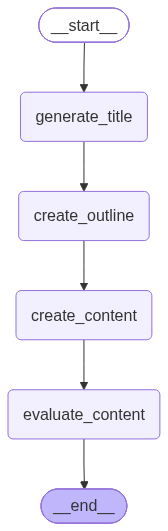

In [49]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())